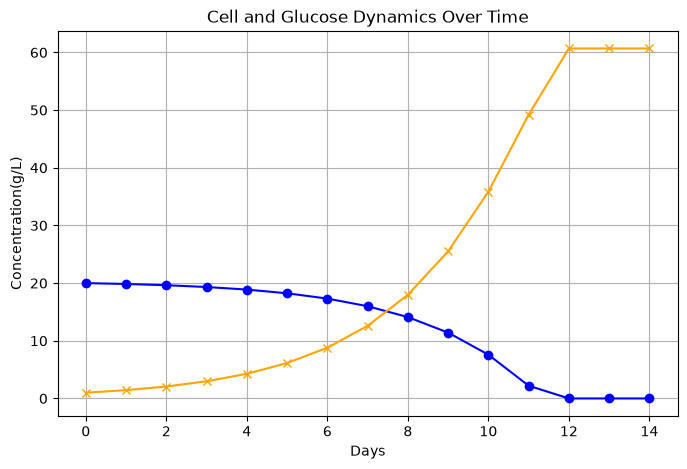

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))


# Initial conditions
glucose[0] = 20.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
glucose_consumption_rate = 0.15  # g/L per million cells per day

mu_max = 0.4 # g/L 
Ks = 2.0 # g/L

# Simple exponential growth model
for j in range(1, len(days)):
    mu = mu_max * glucose[j-1] / (Ks + glucose[j-1])  # Monod equation for growth rate
    cells[j] = cells[j-1] * np.exp(mu)  # Cell growth
    glucose[j] = glucose[j-1] - (glucose_consumption_rate * cells[j-1])  # Glucose consumption
    if glucose[j] < 0:
        glucose[j] = 0  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o",color='blue')
plt.plot(days, cells, marker="x", color='orange')
plt.title("Cell and Glucose Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration(g/L)")
plt.grid()
plt.show()